### Setup: imports and settings

In [1]:
import hashlib, urllib.request
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

SEED = 42

def set_seed():
    np.random.seed(SEED)
    torch.manual_seed(SEED)

def check(description, condition):
    print("PASS " if condition else "CHECK", description)

set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR = Path("lab12_data")
DATA_DIR.mkdir(exist_ok=True)
torch.hub.set_dir(str(DATA_DIR / "torch"))
print("device:", DEVICE)

device: cuda


### Setup: load the dataset

In [2]:
URL = "https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1"
FILE = DATA_DIR / "pneumoniamnist_64.npz"
if not FILE.exists():
    urllib.request.urlretrieve(URL, FILE)
assert hashlib.md5(FILE.read_bytes()).hexdigest() == "8f4eceb4ccffa70c672198ea285246c6"

data = np.load(FILE)
SPLITS = ("train", "val", "test")
IMAGES = {s: data[f"{s}_images"] for s in SPLITS}
LABELS = {s: data[f"{s}_labels"].ravel().astype(int) for s in SPLITS}

### Exercise 1.1: Split summary

In [3]:
def split_summary():
    rows = []
    for s in SPLITS:
        y = LABELS[s]
        rows.append({"split": s, "images": len(y), "normal": (y == 0).sum(),
                     "pneumonia": (y == 1).sum(), "pneumonia_fraction": y.mean()})
    return pd.DataFrame(rows)

summary = split_summary()
display(summary)
check("train has 4,708 images", summary.images[0] == 4708)
check("train has 3,494 pneumonia images", summary.pneumonia[0] == 3494)

,split,images,normal,pneumonia,pneumonia_fraction
0,train,4708,1214,3494,0.742141
1,val,524,135,389,0.742366
2,test,624,234,390,0.625000


PASS  train has 4,708 images
PASS  train has 3,494 pneumonia images


### Part 1: Sample training images

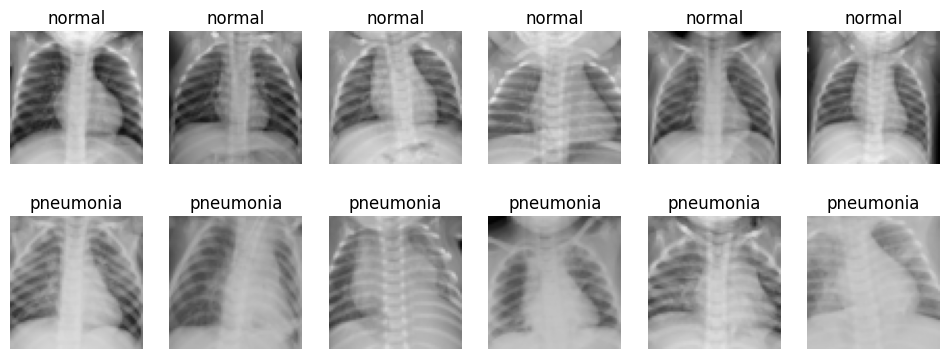

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for row, label in enumerate((0, 1)):
    idx = np.random.choice(np.flatnonzero(LABELS["train"] == label), 6, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(IMAGES["train"][i], cmap="gray", vmin=0, vmax=255)
        ax.set_title("pneumonia" if label else "normal")
        ax.axis("off")
plt.show()

### Exercise 1.2: Answer

1. One row is one X-ray image, not one child. A child can have more than one image and the files have no patient IDs, so 4,708 images does not mean 4,708 children.
2. Val was cut randomly from the same pool as train, so images of the same child could be in both. The model may partly recognise what it has already seen, which makes val results look better than they should.
3. PPV will change, because it depends on prevalence (0.742 in val, 0.625 in test), even if the model stays the same.
4. No. 62-74% pneumonia is far higher than a normal children's clinic would see. With lower prevalence there would be more false alarms per true case, so PPV would drop.

### Exercise 2.1: Metrics at a threshold

In [5]:
def binary_metrics(y_true, p, threshold=0.5):
    y_true = np.asarray(y_true)
    y_hat = (np.asarray(p) >= threshold).astype(int)
    tp = int(((y_hat == 1) & (y_true == 1)).sum())
    fn = int(((y_hat == 0) & (y_true == 1)).sum())
    tn = int(((y_hat == 0) & (y_true == 0)).sum())
    fp = int(((y_hat == 1) & (y_true == 0)).sum())
    auroc = roc_auc_score(y_true, p) if len(np.unique(p)) > 1 else 0.5
    div = lambda a, b: a / b if b else None
    return {"auroc": auroc, "sensitivity": div(tp, tp + fn), "specificity": div(tn, tn + fp),
            "ppv": div(tp, tp + fp), "npv": div(tn, tn + fn), "accuracy": (tp + tn) / len(y_true),
            "tp": tp, "fn": fn, "tn": tn, "fp": fp}

toy = binary_metrics([1, 1, 1, 0, 0], [0.9, 0.8, 0.2, 0.6, 0.1])
check("sensitivity 2/3", abs(toy["sensitivity"] - 2 / 3) < 1e-9)
check("specificity 1/2", toy["specificity"] == 0.5)
check("PPV 2/3", abs(toy["ppv"] - 2 / 3) < 1e-9)
check("NPV 1/2", toy["npv"] == 0.5)

PASS  sensitivity 2/3
PASS  specificity 1/2
PASS  PPV 2/3
PASS  NPV 1/2


### Part 2: Trivial and logistic regression baselines

In [6]:
VAL_PRED, MODELS, NETS = {}, {}, {}

def val_table():
    rows = [{"model": name, **binary_metrics(LABELS["val"], p)} for name, p in VAL_PRED.items()]
    cols = ["model", "auroc", "sensitivity", "specificity", "ppv", "npv", "accuracy"]
    return pd.DataFrame(rows)[cols].round(3)

def add_model(name, predict):
    MODELS[name] = predict
    VAL_PRED[name] = predict(IMAGES["val"])

def pixels_32(images):
    x = images / 255.0
    x = x.reshape(len(x), 32, 2, 32, 2).mean(axis=(2, 4))
    return x.reshape(len(x), -1)

logreg = LogisticRegression(C=0.1, max_iter=2000).fit(pixels_32(IMAGES["train"]), LABELS["train"])
add_model("trivial", lambda images: np.full(len(images), LABELS["train"].mean()))
add_model("logreg_pixels", lambda images: logreg.predict_proba(pixels_32(images))[:, 1])
val_table()

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956


### Exercise 2.2: Answer

1. Accuracy 0.742, sensitivity 1.0, specificity 0. It calls everything pneumonia, so accuracy is just the share of pneumonia images. It never finds a normal image, so it is useless.
2. Every image gets the same score, so the model cannot rank a pneumonia image above a normal one. That is the same as guessing, so AUROC is 0.5.
3. Logistic regression got 0.989 using only pixel values, so this task is quite easy at 64 x 64. The classes must differ in simple overall patterns. A high score here does not prove the model learned anything about the disease.

### Part 3: Prepare tensors and class weight

In [7]:
def to_tensor(images):
    return torch.from_numpy(images).float().div(255).unsqueeze(1)

TENSORS = {s: to_tensor(IMAGES[s]) for s in SPLITS}
TARGETS = {s: torch.from_numpy(LABELS[s]).float() for s in SPLITS}
TRAIN_MEAN = TENSORS["train"].mean().item()
TRAIN_STD = TENSORS["train"].std().item()

n_pos = LABELS["train"].sum()
n_neg = len(LABELS["train"]) - n_pos
POS_WEIGHT = torch.tensor([n_neg / n_pos], dtype=torch.float32)
print("pos_weight:", POS_WEIGHT.item())

pos_weight: 0.3474527895450592


### Part 3: Small CNN model

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.mean, self.std = mean, std

        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(64, 1)

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.head(self.features(x).flatten(1)).squeeze(1)

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

cnn = SmallCNN(TRAIN_MEAN, TRAIN_STD)
print("SmallCNN parameters:", count_params(cnn))

SmallCNN parameters: 23585


### Part 3: Training and prediction functions

In [9]:
@torch.no_grad()
def predict_proba(model, x, batch_size=256):
    model.eval()
    out = [torch.sigmoid(model(x[i:i + batch_size].to(DEVICE))).cpu() for i in range(0, len(x), batch_size)]
    return torch.cat(out).numpy()

def train_model(model, epochs, lr, augment=None):
    set_seed()
    model = model.to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(DEVICE))
    loader = DataLoader(TensorDataset(TENSORS["train"], TARGETS["train"]), batch_size=128, shuffle=True)
    history, best_auroc = [], -1
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment:
                xb = augment(xb)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        p_val = predict_proba(model, TENSORS["val"])
        train_loss = total / len(TARGETS["train"])
        val_loss = F.binary_cross_entropy(torch.tensor(p_val).clamp(1e-7, 1 - 1e-7), TARGETS["val"]).item()
        val_auroc = roc_auc_score(LABELS["val"], p_val)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_auroc": val_auroc})
        print(f"epoch {epoch}  train loss {train_loss:.3f}  val loss {val_loss:.3f}  val AUROC {val_auroc:.3f}")
        if val_auroc > best_auroc:
            best_auroc, best_state = val_auroc, deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

def add_net(name, net):
    NETS[name] = net
    add_model(name, lambda images: predict_proba(net, to_tensor(images)))

def plot_history(h, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    a1.plot(h.epoch, h.train_loss, "o-", label="train (weighted)")
    a1.plot(h.epoch, h.val_loss, "o-", label="validation")
    a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend()
    a2.plot(h.epoch, h.val_auroc, "o-", color="tab:green")
    a2.set_xlabel("epoch"); a2.set_ylabel("validation AUROC")
    fig.suptitle(title)
    plt.show()

### Part 3: Train the small CNN

epoch 1  train loss 0.194  val loss 0.379  val AUROC 0.958


epoch 2  train loss 0.143  val loss 0.246  val AUROC 0.965


epoch 3  train loss 0.121  val loss 0.265  val AUROC 0.971


epoch 4  train loss 0.103  val loss 0.211  val AUROC 0.977


epoch 5  train loss 0.097  val loss 0.185  val AUROC 0.977


epoch 6  train loss 0.087  val loss 0.153  val AUROC 0.986


... (5 outputs left out)

epoch 12  train loss 0.061  val loss 0.121  val AUROC 0.989


epoch 13  train loss 0.062  val loss 0.230  val AUROC 0.984


epoch 14  train loss 0.066  val loss 0.400  val AUROC 0.985


epoch 15  train loss 0.063  val loss 0.110  val AUROC 0.992
kept epoch: 15


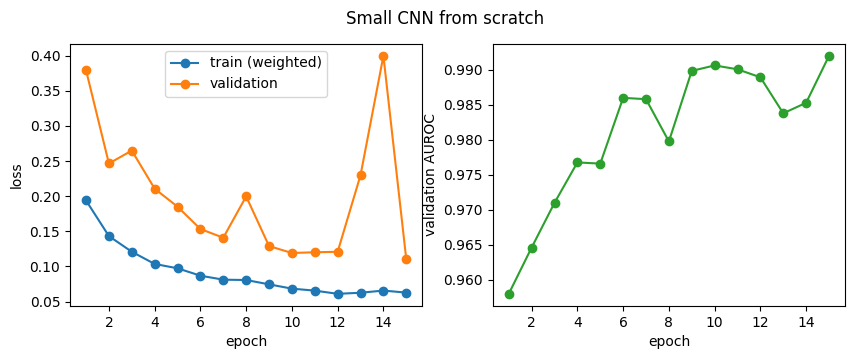

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.911,0.970,0.961,0.968


In [10]:
cnn, hist_cnn = train_model(cnn, epochs=15, lr=1e-3)
add_net("cnn_scratch", cnn)
print("kept epoch:", hist_cnn.epoch[hist_cnn.val_auroc.idxmax()])
plot_history(hist_cnn, "Small CNN from scratch")
val_table()

### Exercise 3.1: Answer

1. Epoch 15 was kept because it had the highest val AUROC (0.992). It happens to be the last epoch here, but it was picked for its AUROC and not for being last.
2. No clear overfitting. Train loss falls from 0.194 to about 0.063, but val loss jumps around: 0.230 and 0.400 at epochs 13-14, then back to 0.110 at epoch 15. AUROC also dips to about 0.985 at those epochs. Val loss is noisy rather than steadily rising, and more epochs might show overfitting.
3. Yes, but only by 0.003 (0.992 vs 0.989). That is too small to justify a neural network on AUROC alone, though NPV did improve (0.961 vs 0.924).
4. The CNN has 23,585 parameters and only 4,708 images, so it has enough capacity to memorise the training data. That is why we watch val data and keep the best epoch.

### Part 4: Pretrained ResNet-18 model

In [11]:
class PretrainedResNet(nn.Module):
    def __init__(self, weights=ResNet18_Weights.IMAGENET1K_V1):
        super().__init__()
        self.backbone = resnet18(weights=weights)
        self.backbone.fc = nn.Linear(512, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = F.interpolate(x, size=128, mode="bilinear").repeat(1, 3, 1, 1)
        return self.backbone((x - self.mean) / self.std).squeeze(1)

resnet = PretrainedResNet()
print("ResNet-18 parameters:", count_params(resnet))

ResNet-18 parameters: 11177025


### Exercise 4.1: Freeze the backbone

In [12]:
def set_backbone_trainable(model, trainable):
    for name, p in model.backbone.named_parameters():
        if not name.startswith("fc."):
            p.requires_grad = trainable

set_backbone_trainable(resnet, False)
check("frozen: only the 512 + 1 head parameters are trainable", count_params(resnet, trainable_only=True) == 513)

PASS  frozen: only the 512 + 1 head parameters are trainable


### Part 4: Stage A - Feature extraction

epoch 1  train loss 0.263  val loss 0.378  val AUROC 0.947


epoch 2  train loss 0.144  val loss 0.270  val AUROC 0.969


epoch 3  train loss 0.119  val loss 0.233  val AUROC 0.974


epoch 4  train loss 0.107  val loss 0.215  val AUROC 0.976


epoch 5  train loss 0.099  val loss 0.184  val AUROC 0.977


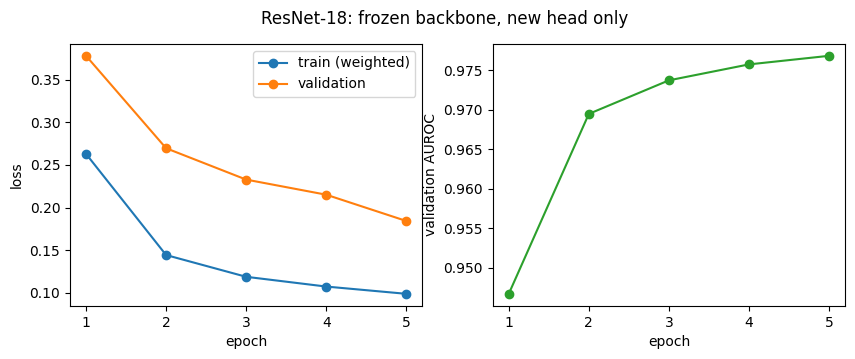

In [13]:
resnet, hist_head = train_model(resnet, epochs=5, lr=1e-3)
add_net("resnet_features", resnet)
plot_history(hist_head, "ResNet-18: frozen backbone, new head only")

### Part 4: Stage B - Fine-tuning

trainable parameters: 11177025


epoch 1  train loss 0.061  val loss 0.066  val AUROC 0.998


epoch 2  train loss 0.012  val loss 0.108  val AUROC 0.997


epoch 3  train loss 0.005  val loss 0.065  val AUROC 0.998


epoch 4  train loss 0.001  val loss 0.052  val AUROC 0.998


epoch 5  train loss 0.001  val loss 0.056  val AUROC 0.998


epoch 6  train loss 0.000  val loss 0.056  val AUROC 0.998


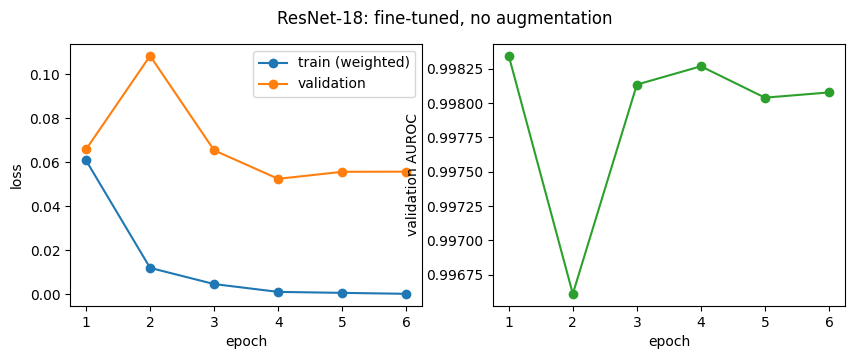

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.911,0.970,0.961,0.968
3,resnet_features,0.977,0.951,0.889,0.961,0.863,0.935
4,resnet_finetuned,0.998,0.974,0.993,0.997,0.931,0.979


In [14]:
resnet_ft = deepcopy(resnet)
set_backbone_trainable(resnet_ft, True)
print("trainable parameters:", count_params(resnet_ft, trainable_only=True))
resnet_ft, hist_ft = train_model(resnet_ft, epochs=6, lr=1e-4)
add_net("resnet_finetuned", resnet_ft)
plot_history(hist_ft, "ResNet-18: fine-tuned, no augmentation")
val_table()

### Exercise 4.2: Choose augmentations

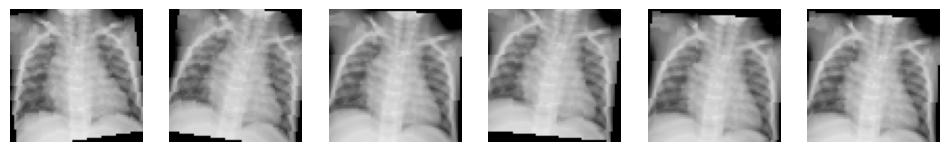

PASS  some augmentation chosen


In [15]:
def make_augment(max_rotation_deg=0, max_shift_frac=0, contrast=0, hflip=False):
    tf = T.Compose([T.RandomAffine(max_rotation_deg, translate=(max_shift_frac, max_shift_frac)),
                    T.ColorJitter(contrast=contrast),
                    T.RandomHorizontalFlip(0.5 if hflip else 0)])
    return lambda x: torch.stack([tf(img) for img in x])

AUGMENT_SETTINGS = {"max_rotation_deg": 10, "max_shift_frac": 0.05, "contrast": 0.1, "hflip": False}
augment = make_augment(**AUGMENT_SETTINGS)

shown = augment(TENSORS["train"][:1].repeat(6, 1, 1, 1))
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, img in zip(axes, shown):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()
check("some augmentation chosen", any(AUGMENT_SETTINGS.values()))

### Part 4: Stage C - Fine-tuning with augmentation

epoch 1  train loss 0.082  val loss 0.179  val AUROC 0.993


epoch 2  train loss 0.043  val loss 0.093  val AUROC 0.997


epoch 3  train loss 0.030  val loss 0.128  val AUROC 0.997


epoch 4  train loss 0.025  val loss 0.110  val AUROC 0.997


epoch 5  train loss 0.022  val loss 0.095  val AUROC 0.997


epoch 6  train loss 0.018  val loss 0.079  val AUROC 0.997


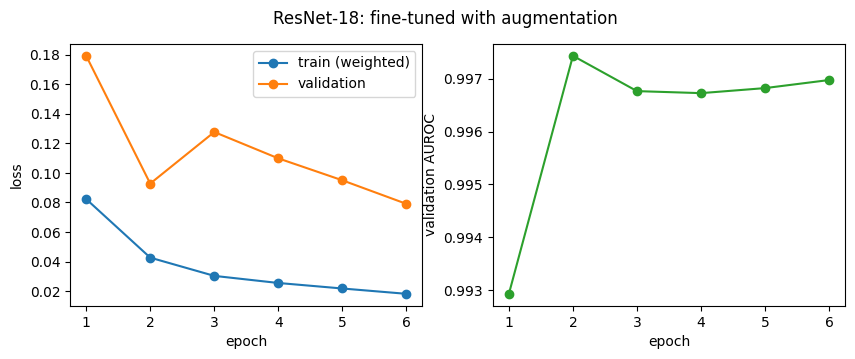

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.911,0.970,0.961,0.968
3,resnet_features,0.977,0.951,0.889,0.961,0.863,0.935
4,resnet_finetuned,0.998,0.974,0.993,0.997,0.931,0.979
5,resnet_finetuned_aug,0.997,0.961,0.993,0.997,0.899,0.969


In [16]:
resnet_aug = deepcopy(resnet)
set_backbone_trainable(resnet_aug, True)
resnet_aug, hist_aug = train_model(resnet_aug, epochs=6, lr=1e-4, augment=augment)
add_net("resnet_finetuned_aug", resnet_aug)
plot_history(hist_aug, "ResNet-18: fine-tuned with augmentation")
val_table()

### Optional extension: ResNet-18 from random weights

epoch 1  train loss 0.141  val loss 0.117  val AUROC 0.993


epoch 2  train loss 0.060  val loss 0.107  val AUROC 0.992


epoch 3  train loss 0.039  val loss 1.164  val AUROC 0.961


epoch 4  train loss 0.045  val loss 0.119  val AUROC 0.990


epoch 5  train loss 0.032  val loss 0.173  val AUROC 0.995


epoch 6  train loss 0.035  val loss 0.118  val AUROC 0.997


epoch 7  train loss 0.021  val loss 0.268  val AUROC 0.995


epoch 8  train loss 0.019  val loss 0.094  val AUROC 0.996


epoch 9  train loss 0.017  val loss 0.116  val AUROC 0.994


epoch 10  train loss 0.018  val loss 0.116  val AUROC 0.992


epoch 11  train loss 0.014  val loss 0.242  val AUROC 0.993


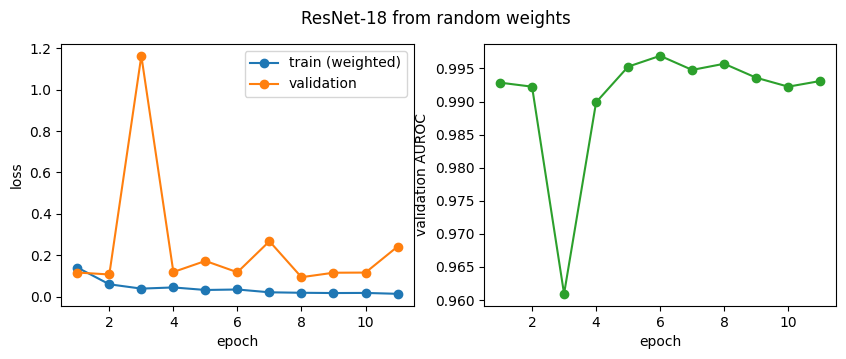

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.911,0.970,0.961,0.968
3,resnet_features,0.977,0.951,0.889,0.961,0.863,0.935
4,resnet_finetuned,0.998,0.974,0.993,0.997,0.931,0.979
5,resnet_finetuned_aug,0.997,0.961,0.993,0.997,0.899,0.969
6,resnet_random_init,0.997,0.995,0.822,0.942,0.982,0.950


In [17]:
resnet_rand = PretrainedResNet(weights=None)
resnet_rand, hist_rand = train_model(resnet_rand, epochs=11, lr=1e-3)
add_net("resnet_random_init", resnet_rand)
plot_history(hist_rand, "ResNet-18 from random weights")
val_table()

### Exercise 4.3: Answer

1. Rotation of 10 degrees and shift of 5% because patient position and framing vary a little between X-rays. Contrast of 10% because exposure differs between machines. No flip, because the heart is on the left side and a flipped image is not real anatomy.
2. Ranking: resnet_finetuned 0.998, resnet_finetuned_aug 0.997, cnn_scratch 0.992, logreg_pixels 0.989, resnet_features 0.977. Fine-tuning beat the CNN, but feature extraction alone was worse than both the CNN and logistic regression. Fine-tuning clearly helped compared with feature extraction (0.977 to 0.998).
3. Augmentation did not help (0.997 vs 0.998). With only 6 epochs and 524 val images, a 0.001 difference is too small to trust either way.
4. Stage A trains 513 parameters and Stage B trains 11,177,025. Stage A still works because ImageNet features such as edges and textures are useful for X-rays too, and only one linear layer has to be learned.
5. Train the same ResNet-18 from random weights. I did this: it reached 0.997 against 0.998, so here most of the gain seems to come from the architecture and not the pretraining. It was less stable though (AUROC fell to 0.961 at epoch 3), and its specificity at 0.5 was only 0.822 against 0.993.

### Exercise 5.1: Choose the model and threshold

In [18]:
def threshold_for_sensitivity(y_true, p, target):
    fpr, tpr, thresholds = roc_curve(y_true, p)
    ok = np.flatnonzero(tpr >= target)
    return float(min(thresholds[ok[0]], 1.0))

table = val_table().sort_values("auroc", ascending=False)
display(table)

CHOSEN_MODEL = table.model.iloc[0]   # highest validation AUROC
TARGET_SENSITIVITY = 0.95

THRESHOLD = threshold_for_sensitivity(LABELS["val"], VAL_PRED[CHOSEN_MODEL], TARGET_SENSITIVITY)
val_at_threshold = binary_metrics(LABELS["val"], VAL_PRED[CHOSEN_MODEL], THRESHOLD)
print("chosen:", CHOSEN_MODEL, "| threshold:", round(THRESHOLD, 3))
print(val_at_threshold)

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
4,resnet_finetuned,0.998,0.974,0.993,0.997,0.931,0.979
5,resnet_finetuned_aug,0.997,0.961,0.993,0.997,0.899,0.969
6,resnet_random_init,0.997,0.995,0.822,0.942,0.982,0.950
2,cnn_scratch,0.992,0.987,0.911,0.970,0.961,0.968
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
3,resnet_features,0.977,0.951,0.889,0.961,0.863,0.935
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742


chosen: resnet_finetuned | threshold: 0.598
{'auroc': 0.9983433304770065, 'sensitivity': 0.9717223650385605, 'specificity': 1.0, 'ppv': 1.0, 'npv': 0.9246575342465754, 'accuracy': 0.9790076335877863, 'tp': 378, 'fn': 11, 'tn': 135, 'fp': 0}


### Exercise 5.1: Answer

I chose resnet_finetuned because it had the highest val AUROC (0.998). I set target sensitivity to 0.95 because missing pneumonia is worse than an extra review. The threshold 0.598 gives sensitivity 0.972 on val, and specificity stays at 1.000 (0 false positives, 11 missed), so on val there was no cost in specificity. I do not expect that to hold on new data.

### Part 5: Single test evaluation

In [19]:
y_test = LABELS["test"]
p_test = MODELS[CHOSEN_MODEL](IMAGES["test"])
test_at_threshold = binary_metrics(y_test, p_test, THRESHOLD)

rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(p_test), len(p_test))
    boot.append(roc_auc_score(y_test[i], p_test[i]))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

final = pd.DataFrame([{"set": "validation", **val_at_threshold}, {"set": "test", **test_at_threshold}])
final.insert(1, "model", CHOSEN_MODEL)
final.insert(2, "threshold", THRESHOLD)
display(final.round(3))
print(f"test AUROC {test_at_threshold['auroc']:.3f} (95% CI {ci_low:.3f}-{ci_high:.3f})")

pd.concat([val_table().assign(set="validation", threshold=0.5), final.round(3)]).to_csv(DATA_DIR / "lab12_results.csv", index=False)
if CHOSEN_MODEL in NETS:
    torch.save(NETS[CHOSEN_MODEL].state_dict(), DATA_DIR / "lab12_chosen_model.pt")

,set,model,threshold,auroc,sensitivity,specificity,ppv,npv,accuracy,tp,fn,tn,fp
0,validation,resnet_finetuned,0.598,0.998,0.972,1.000,1.000,0.925,0.979,378,11,135,0
1,test,resnet_finetuned,0.598,0.982,0.995,0.803,0.894,0.989,0.923,388,2,188,46


test AUROC 0.982 (95% CI 0.973-0.990)


### Exercise 5.2: Answer

1. Sensitivity went from 0.972 to 0.995, specificity from 1.000 to 0.803, and PPV from 1.000 to 0.894. Specificity changed the most: 46 of 234 normal images were called pneumonia.
2. First, val came from the same pool as train, while test came from the separate held-out set, so val was the easier and more optimistic set. Second, test has lower prevalence (0.625 vs 0.742), which lowers PPV. The threshold was also tuned on val, so it suits val better.
3. The CI is 0.973-0.990, about 0.017 wide. So a claim like "model A beats model B by 0.01" means little, because that gap is within the noise.
4. No. Test comes from the same source dataset. External validation needs data from different hospitals, machines and patients that had no part in building the model.
5. Before real use it would need: validation at other hospitals on full-resolution images with patient-level splits, a prospective study in a real clinical workflow, and regulatory approval with monitoring after deployment.

### Part 6: Reflection

**Data:** PneumoniaMNIST 64 x 64, with 4,708 train, 524 val and 624 test images. Train and val were split randomly by image, and there are no patient IDs.

**Preprocessing:** pixels scaled to 0-1, resized to 128 x 128, copied to 3 channels, ImageNet normalisation.

**Model:** ResNet-18 pretrained on ImageNet with a new one-logit head. No augmentation.

**Training:** 5 epochs on the head only (lr 1e-3), then 6 epochs on all layers (lr 1e-4), with weighted loss (pos_weight 0.347). Kept the epoch with the best val AUROC.

**Threshold:** 0.598, chosen on val for a target sensitivity of 0.95.

**Test results:** AUROC 0.982 (95% CI 0.973-0.990), sensitivity 0.995, specificity 0.803, PPV 0.894, NPV 0.989.

**Limitations:** one source of paediatric data, very low resolution, image-level splits, 46 false positives out of 234 normal images, and no external validation. This is a class exercise and not a diagnostic tool.